# Main Imports

In [253]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Short Questions

## 1. A Couple of examples of plots

### Jake Vanderplas book

#### 04.08 Multiple subplots

Having multiple subplots can be useful to organize data, the main conventional way to do so is by using `plt.subplot` or `plt.subplots`, discretizing a plot into a grid of multiple subplots

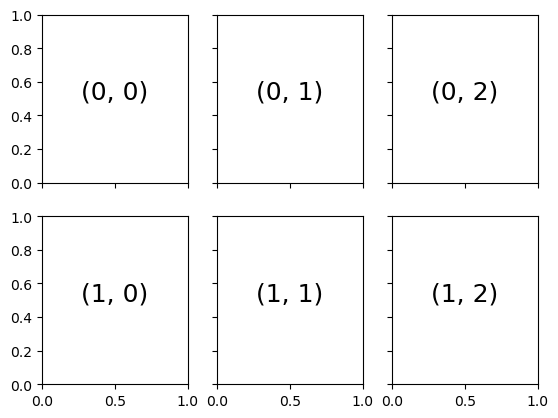

In [254]:
grid = plt.GridSpec(2, 3, wspace=0.4, hspace=0.3)

fig, ax = plt.subplots(2, 3, sharex='col', sharey='row')

for i in range(2):
    for j in range(3):
        ax[i, j].text(0.5, 0.5, str((i, j)),
                      fontsize=18, ha='center')

Additionally, using `plt.GridSpec` allows you to freely allocate space for different `plt.subplot`.

#### 04.09 Text and Annotation

Assuming we define a graph using for instance `fig, ax = plt.subplots(figsize=(X, Y))`, then, one can use `plt.text` or `ax.text` to add text relative to some data point.

Other options such as a combination of `plt.arrow` and `plt.annotate` allows more control with respect to the annotating text (i.e. putting the annotation in a certain manner, and linking some data point and the text with an arrow).

#### 04.10 Customizing Ticks

In matplotlib, ticks represent the different "markers" (such as the scale legend on axes for instance) used in plots.

Matplotlib uses "major" (the main ones, bigger, "essential") and "minor" (situational) tickmarks.

When displaying some plots, one can remove the abscissa and ordinate marking ticks using (targetting major tickmarks):

```
ax = plt.axes()
ax.yaxis.set_major_locator(plt.NullLocator())
ax.xaxis.set_major_formatter(plt.NullFormatter())
```


Additionally, When using different subplots, one can use:

```
for axi in ax.flat:
    axi.xaxis.set_major_locator(plt.MaxNLocator(3))
    axi.yaxis.set_major_locator(plt.MaxNLocator(3))
```

to only display 3 tickmark measure per graph (think of only displaying 3 abscissa or ordinate main values on the graph's scale).

Using `plt.MultipleLocator` allows more flexibility when it comes to how many (and which exact values of) tickmarks one wants to display.

More examples of options on the book or on the main [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axis.Axis.set_major_locator.html). 

#### 04.11 Settings and Stylesheets

Matplotlib gives a decent range of customization. Namely, using `rcParams` changes the default parameters, i.e. the default colors of different components, but also the default style of lines, ticks, etc.

One can also use one of the predefined set of styles, in `plt.style.available` inside a `plt.style.context` method (specifics can also be changed using dictionaries and/or using some `rcParams` components). Running the code below will give you one of the random style presets with examples in basic plotting, histogram and scatter plots.

Nice, you got the _mpl-gallery-nogrid style!


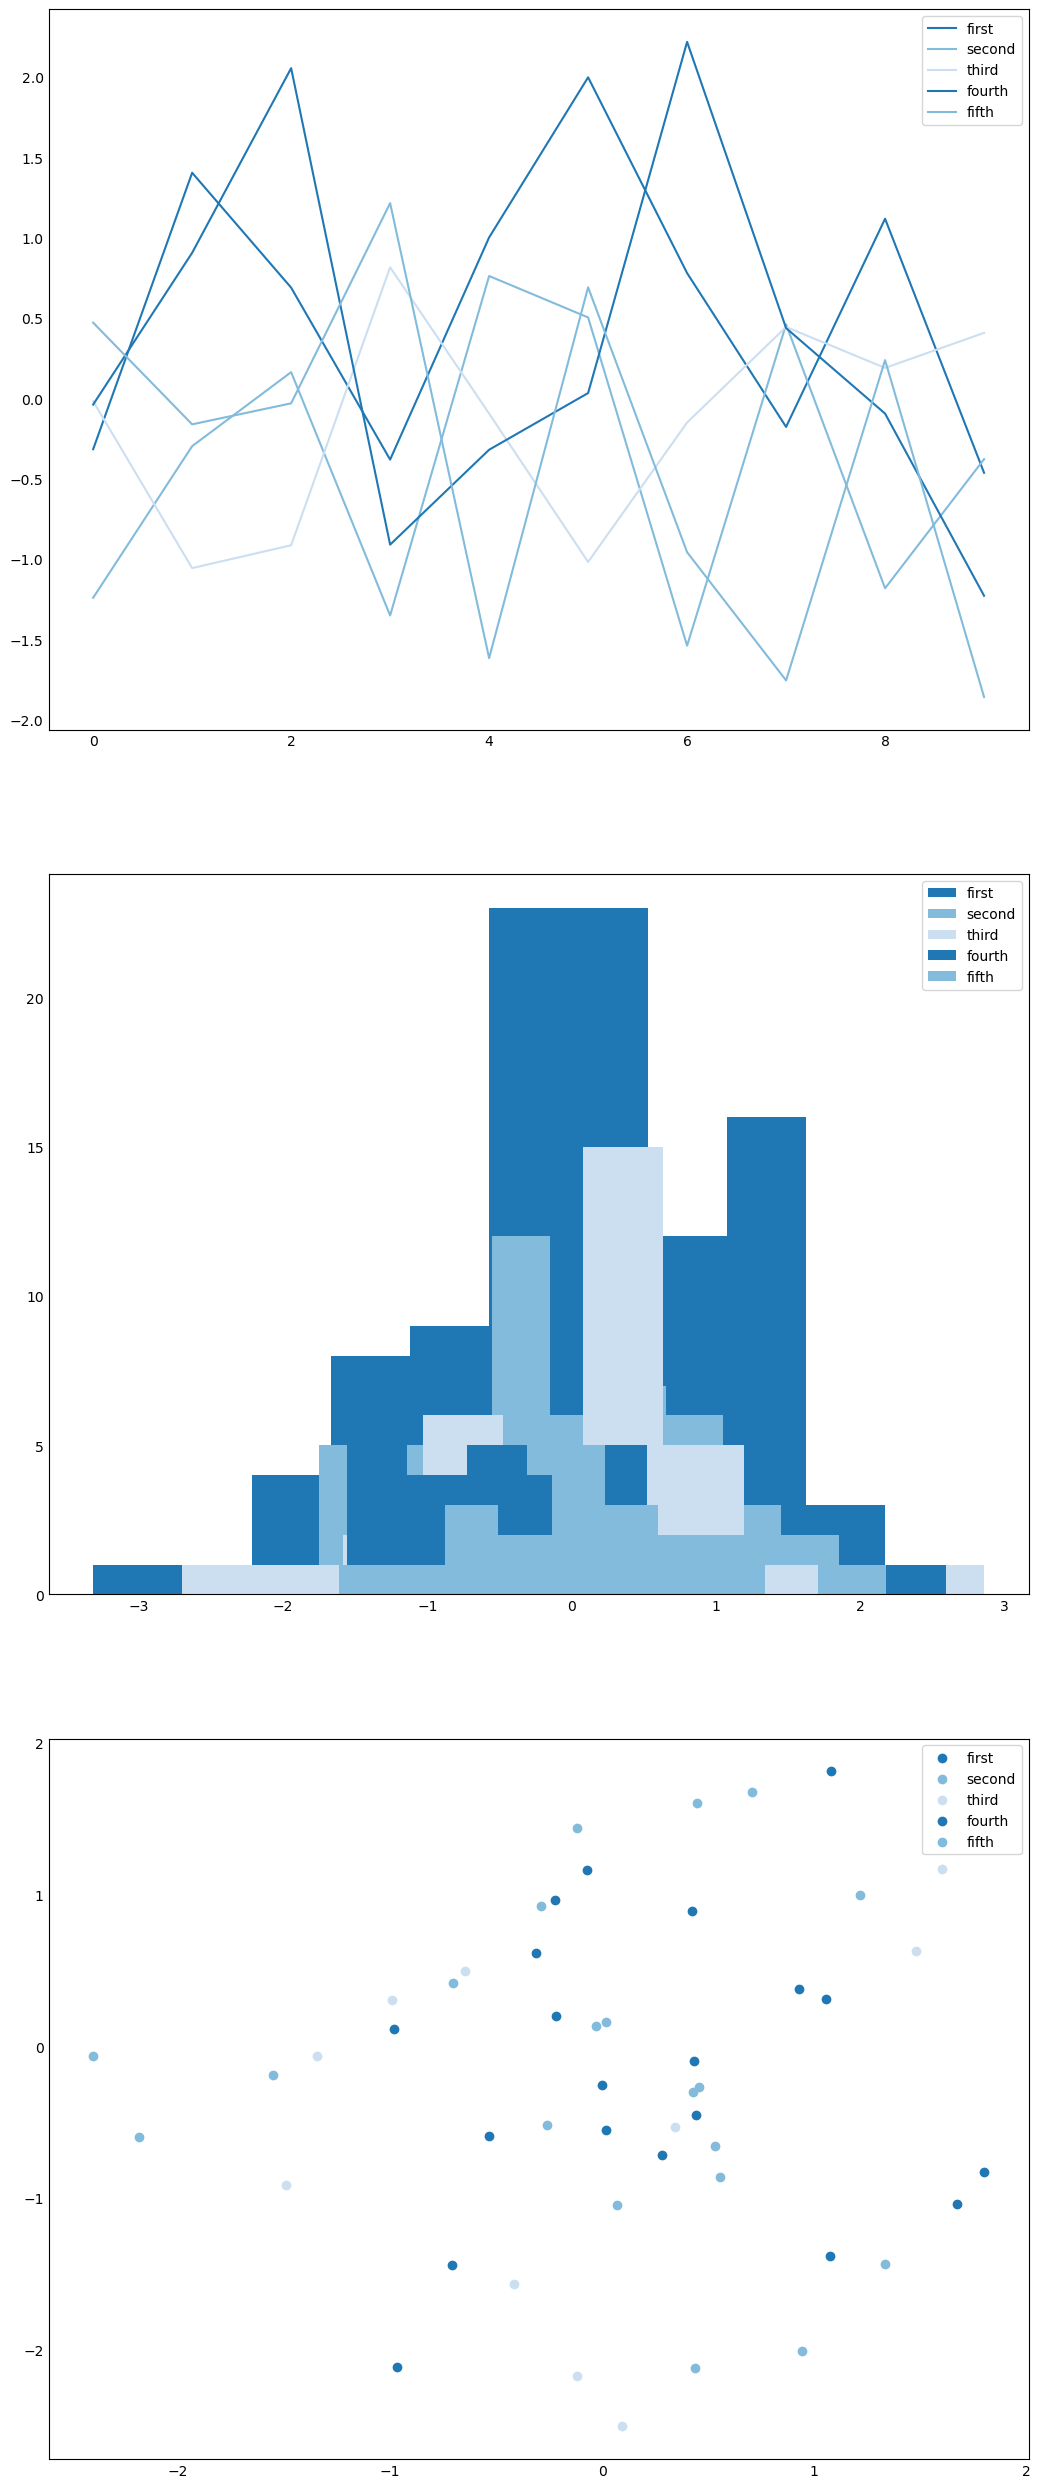

In [255]:
with plt.style.context(style := str(np.random.choice(plt.style.available))):
    print(f"Nice, you got the {style} style!")
    fig, ax = plt.subplots(3, 1, figsize=(10, 25))
    for i in range(5):
        ax[0].plot(np.random.randn(10))
        ax[1].hist(np.random.randn(100 // (i+1)))
        ax[2].scatter(np.random.randn(10), np.random.randn(10))
    ax[0].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    ax[1].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    ax[2].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    

#### 04.11 Three-Dimensional Plotting

Some matplotlib additional library allows for 3D-plotting. The only main fundamental change in plotting stems in a new `z` value to take into account when plotting.

One can plot predefined functions in numpy, or can define their own and then plot them directly.

For instance, one can plot functions in 3D as such

Text(0.5, 0, 'z')

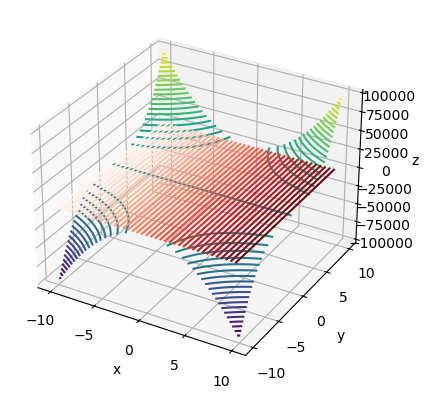

In [256]:
from mpl_toolkits import mplot3d

def f(x, y):
    return x + 1

def g(x, y):
    return y**3 * x**2

x, y = np.linspace(-10, 10, 100), np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)

Z1 = f(X, Y)
Z2 = g(X, Y)

fig = plt.figure()
ax = plt.axes(projection='3d')
ax.contour3D(X, Y, Z1, 40, cmap='Reds')
ax.contour3D(X, Y, Z2, 40, cmap='viridis')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

# 2. Good Practices

### A. Copying

Python's `=` assigning values between variables does not create distinct copies. By default, this results in shallow copies, where one variable's object gets "intertwined" with another. This is because `=` only reassigns pointer values. Here, changing x also impacts y:

In [257]:
x = [0] * 10
y = x

x[0] = 1
y

[1, 0, 0, 0, 0, 0, 0, 0, 0, 0]

One may prefer to create a deep copy of x before assigning it to y, so that y is resilient to x's changes:

In [258]:
x = [0] * 10
y = x.copy()

x[0] = 1
y

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

### B. Object and memory management

When working with limited memory or time, using some methods may be detrimental. With lists for instance, using + creates a new list instance.

In [259]:
import time

start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

x += y

print(time.time() - start_time)

0.11939525604248047


In [260]:
start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

for e in y:
    x.append(e)

print(time.time() - start_time)

2.8659820556640625


In [261]:
start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

x.extend(y)

print(time.time() - start_time)

0.22444891929626465


Of course, efficiency here is space-dependent. Take a smaller y, and one will get different results.

In [262]:
import time

start_time = time.time()

x = [0] * 100000
y = [0] * 10

x += y

print(time.time() - start_time)

0.09589076042175293


In [263]:
start_time = time.time()

x = [0] * 100000
y = [0] * 10

for e in y:
    x.append(e)

print(time.time() - start_time)

0.0001590251922607422


In [264]:
start_time = time.time()

x = [0] * 100000
y = [0] * 10

x.extend(y)

print(time.time() - start_time)

0.0001423358917236328


With a bigger y, the append method (in a for loop) was losing, probably because of variable attributions with e. With a smaller y though, creating a new list through + was simply too inefficient. Extend seems to be the preferred candidate. Of course, each of these methods can be twisted for one's own needs, especially because of space-dependency (one may need to create a whole new array, etc.).

### C. Calibrating with respect to machine precision

Float operations are always odd, especially at extreme scales. One may need to choose a more precise float scale if they want more precision (although using more space).

In [268]:
A1 = 0.000000003 - 0.000000001
A1

1.9999999999999997e-09

In [266]:
A2 = np.float128(0.000000003) - np.float128(0.000000001)
A2

np.longdouble('1.9999999999999999178e-09')

In [267]:
A2 - A1

np.longdouble('2.0679515313825691872e-25')

Here, the precision is in the 10**(-25), which can be tolerable for some, and not for others. It's important to keep these kind of discrepancies in mind.

### D. When in doubt, use NumPy, it's faster

NumPy handles array operations better, especially operations between arrays or complex functions. A simple example with x**2 (not even counting np.exp, np.sin, etc.).

In [ ]:
def f(x):
    return x**2

In [351]:
time_start = time.time()

a = [f(i) for i in range(100001)]

print(n1 := time.time() - time_start)

0.005905628204345703


In [352]:
time_start = time.time()

a = f(np.linspace(0, 100000, 100001))

print(n2 := time.time() - time_start)

0.0012619495391845703


In [353]:
print(f"Raw time difference: {n1 - n2}")

Raw time difference: 0.004643678665161133


This may count for optimization, over even larger arrays and more complex functions.